In [6]:

import sys
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import IMAGE_DIR, METADATA_PATH, GROUND_TRUTH_PATH

RANDOM_STATE = 42
BATCH_SIZE = 16
EPOCHS = 5
LEARNING_RATE = 1e-4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", PROJECT_ROOT)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Training will use CPU.")


Project: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Device: cpu
GPU unavailable. Training will use CPU.


In [7]:

metadata = pd.read_csv(METADATA_PATH)
ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

label_columns = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

ground_truth["label"] = ground_truth[label_columns].idxmax(axis=1)

dermoscopic = metadata.loc[
    metadata["image_type"].str.lower().eq("dermoscopic")
].copy()

data = dermoscopic.merge(
    ground_truth[["lesion_id", "label"]],
    on="lesion_id",
    how="inner",
    validate="one_to_one"
).reset_index(drop=True)

print("Total lesions:", len(data))
print("Number of classes:", data["label"].nunique())

display(data["label"].value_counts().to_frame("Count"))


Total lesions: 5240
Number of classes: 11


,Count
label,
BCC,2522
NV,746
BKL,544
SCCKA,473
MEL,450
AKIEC,303
DF,52
INF,50
VASC,47


In [8]:

train_data, temp_data = train_test_split(
    data,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=data["label"]
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_data["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

print("\nLesion overlap:")
print("Train/validation:", len(set(train_data.lesion_id) & set(val_data.lesion_id)))
print("Train/test:", len(set(train_data.lesion_id) & set(test_data.lesion_id)))
print("Validation/test:", len(set(val_data.lesion_id) & set(test_data.lesion_id)))


Training: 3144
Validation: 1048
Test: 1048

Lesion overlap:
Train/validation: 0
Train/test: 0
Validation/test: 0


In [9]:

IMAGE_SIZE = 128

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations ready.")


Image transformations ready.


In [10]:

class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_dir / f"{row['isic_id']}.jpg"

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[row["label"]]

        return image, label


class_names = sorted(data["label"].unique())
class_to_idx = {
    name: index for index, name in enumerate(class_names)
}

idx_to_class = {
    index: name for name, index in class_to_idx.items()
}

print("Classes:", class_names)
print("Number of classes:", len(class_names))


Classes: ['AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']
Number of classes: 11


In [11]:

train_dataset = SkinLesionDataset(
    train_data, IMAGE_DIR, train_transform
)

val_dataset = SkinLesionDataset(
    val_data, IMAGE_DIR, eval_transform
)

test_dataset = SkinLesionDataset(
    test_data, IMAGE_DIR, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 197
Validation batches: 66
Test batches: 66


In [12]:

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

print("Image pipeline working!")


Image batch shape: torch.Size([16, 3, 128, 128])
Label batch shape: torch.Size([16])
First 10 labels: [8, 8, 8, 8, 7, 8, 3, 1, 7, 1]
Image pipeline working!


In [13]:

NUM_CLASSES = len(class_names)

def create_resnet18(unfreeze_layers):
    # Start from fresh ImageNet-pretrained weights every time
    weights = models.ResNet18_Weights.DEFAULT
    model = models.resnet18(weights=weights)

    # Replace the final classification layer
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    # Freeze every parameter
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze only the requested layers
    for name, param in model.named_parameters():
        if name.startswith(unfreeze_layers):
            param.requires_grad = True

    return model.to(device)


# Verify both configurations
model_a = create_resnet18(("layer4", "fc"))
model_b = create_resnet18(("layer3", "layer4", "fc"))

def count_trainable_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

print("Model A (layer4 + fc):")
print("Trainable parameters:", f"{count_trainable_parameters(model_a):,}")

print("\nModel B (layer3 + layer4 + fc):")
print("Trainable parameters:", f"{count_trainable_parameters(model_b):,}")


Model A (layer4 + fc):
Trainable parameters: 8,399,371

Model B (layer3 + layer4 + fc):
Trainable parameters: 10,499,083


In [14]:

train_labels = train_data["label"].map(class_to_idx).to_numpy()

weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_labels
)

class_weights = torch.tensor(
    weights_array,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Class weights:")
for i, name in enumerate(class_names):
    print(f"{name}: {weights_array[i]:.3f}")


Class weights:
AKIEC: 1.570
BCC: 0.189
BEN_OTH: 10.586
BKL: 0.877
DF: 9.220
INF: 9.527
MAL_OTH: 57.164
MEL: 1.059
NV: 0.638
SCCKA: 1.006
VASC: 10.208


In [15]:

def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    return f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )


def train_model(model, model_name):
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.AdamW(trainable_params, lr=LEARNING_RATE)

    best_val_f1 = -1
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    history = []
    epoch_times = []

    checkpoint_path = checkpoint_dir / f"{model_name}_best.pth"

    for epoch in range(EPOCHS):
        model.train()
        epoch_start = time.time()
        running_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)

        val_f1 = evaluate_model(model, val_loader)
        avg_loss = running_loss / len(train_loader)

        history.append({
            "epoch": epoch + 1,
            "loss": avg_loss,
            "val_macro_f1": val_f1,
            "time": epoch_time
        })

        print(
            f"{model_name} | Epoch {epoch + 1}/{EPOCHS} "
            f"| Loss: {avg_loss:.4f} "
            f"| Val Macro-F1: {val_f1:.4f} "
            f"| Time: {epoch_time:.2f}s"
        )

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(best_weights, checkpoint_path)
            print(f"  Best checkpoint saved: {checkpoint_path}")

    model.load_state_dict(best_weights)

    result = {
        "model": model_name,
        "best_val_macro_f1": best_val_f1,
        "best_epoch": best_epoch,
        "avg_epoch_time": sum(epoch_times) / len(epoch_times),
        "history": history
    }

    return model, result

In [16]:
from torchvision import models
import torch.nn as nn

model_a = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model_a.fc = nn.Linear(
    model_a.fc.in_features,
    11
)

# Freeze everything first
for param in model_a.parameters():
    param.requires_grad = False

# Unfreeze layer4 and the classification head
for param in model_a.layer4.parameters():
    param.requires_grad = True

for param in model_a.fc.parameters():
    param.requires_grad = True

model_a = model_a.to(device)

print("Model A initialized successfully!")

Model A initialized successfully!


In [17]:
for name, param in model_a.named_parameters():
    if param.requires_grad:
        print(name)

layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [18]:
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)
print("Checkpoint folder:", checkpoint_dir)

Epochs: 5
Learning rate: 0.0001
Train batches: 197
Validation batches: 66
Device: cpu
Checkpoint folder: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints


In [19]:
model_a, result_a = train_model(
    model_a,
    "resnet18_layer4_fc"
)

print("\nTraining complete!")
print("Best validation Macro-F1:", result_a["best_val_macro_f1"])
print("Best epoch:", result_a["best_epoch"])
print("Average epoch time:", result_a["avg_epoch_time"])

resnet18_layer4_fc | Epoch 1/5 | Loss: 1.9370 | Val Macro-F1: 0.2775 | Time: 44.74s
  Best checkpoint saved: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_layer4_fc_best.pth
resnet18_layer4_fc | Epoch 2/5 | Loss: 1.2109 | Val Macro-F1: 0.3129 | Time: 40.23s
  Best checkpoint saved: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_layer4_fc_best.pth
resnet18_layer4_fc | Epoch 3/5 | Loss: 0.8849 | Val Macro-F1: 0.3386 | Time: 63.12s
  Best checkpoint saved: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_layer4_fc_best.pth
resnet18_layer4_fc | Epoch 4/5 | Loss: 0.6488 | Val Macro-F1: 0.3480 | Time: 49.78s
  Best checkpoint saved: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints\resnet18_layer4_fc_best.pth
resnet18_layer4_fc | Epoch 5/5 | Loss: 0.4895 | Val Macro-F1: 0.3367 | Time: 41.17s

Training complete!
Best validation Macro-F1: 0.34803378448935035
Best epoch: 4
Average epoch time: 47.8061611175537

In [20]:
# Load the best saved checkpoint
checkpoint_path = checkpoint_dir / "resnet18_layer4_fc_best.pth"

model_a.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

model_a.eval()

# Evaluate on the test set
test_f1 = evaluate_model(model_a, test_loader)

print(f"Test Macro-F1: {test_f1:.4f}")

Test Macro-F1: 0.3214


In [19]:

# Experiment A: Unfreeze layer4 + fc
model_a, result_a = train_model(
    model_a,
    "Layer4 + FC"
)

print("\nExperiment A completed!")

# Experiment B: Unfreeze layer3 + layer4 + fc
model_b, result_b = train_model(
    model_b,
    "Layer3 + Layer4 + FC"
)

print("\nExperiment B completed!")


Layer4 + FC | Epoch 1/5 | Loss: 1.9845 | Val Macro-F1: 0.3015 | Time: 37.61s
Layer4 + FC | Epoch 2/5 | Loss: 1.1782 | Val Macro-F1: 0.3114 | Time: 36.01s
Layer4 + FC | Epoch 3/5 | Loss: 0.8198 | Val Macro-F1: 0.3003 | Time: 38.41s
Layer4 + FC | Epoch 4/5 | Loss: 0.7190 | Val Macro-F1: 0.3270 | Time: 40.05s
Layer4 + FC | Epoch 5/5 | Loss: 0.4914 | Val Macro-F1: 0.3517 | Time: 38.94s

Experiment A completed!
Layer3 + Layer4 + FC | Epoch 1/5 | Loss: 1.9577 | Val Macro-F1: 0.2906 | Time: 53.81s
Layer3 + Layer4 + FC | Epoch 2/5 | Loss: 1.1982 | Val Macro-F1: 0.3050 | Time: 52.30s
Layer3 + Layer4 + FC | Epoch 3/5 | Loss: 0.8250 | Val Macro-F1: 0.3374 | Time: 50.87s
Layer3 + Layer4 + FC | Epoch 4/5 | Loss: 0.6206 | Val Macro-F1: 0.3379 | Time: 48.37s
Layer3 + Layer4 + FC | Epoch 5/5 | Loss: 0.4607 | Val Macro-F1: 0.3406 | Time: 51.43s

Experiment B completed!


In [20]:

comparison_df = pd.DataFrame([
    {k: v for k, v in result_a.items() if k != "History"},
    {k: v for k, v in result_b.items() if k != "History"}
])

display(comparison_df.round(4))

# Calculate relative training-time increase
time_a = result_a["Average seconds per epoch"]
time_b = result_b["Average seconds per epoch"]

time_increase = ((time_b - time_a) / time_a) * 100

f1_difference = (
    result_b["Best validation macro-F1"]
    - result_a["Best validation macro-F1"]
)

print(f"Training time increase: {time_increase:.2f}%")
print(f"Validation macro-F1 difference: {f1_difference:.4f}")


,Model,Trainable parameters,Average seconds per epoch,Best validation macro-F1,Best epoch
0,Layer4 + FC,8399371,38.2035,0.3517,5
1,Layer3 + Layer4 + FC,10499083,51.3572,0.3406,5


Training time increase: 34.43%
Validation macro-F1 difference: -0.0112


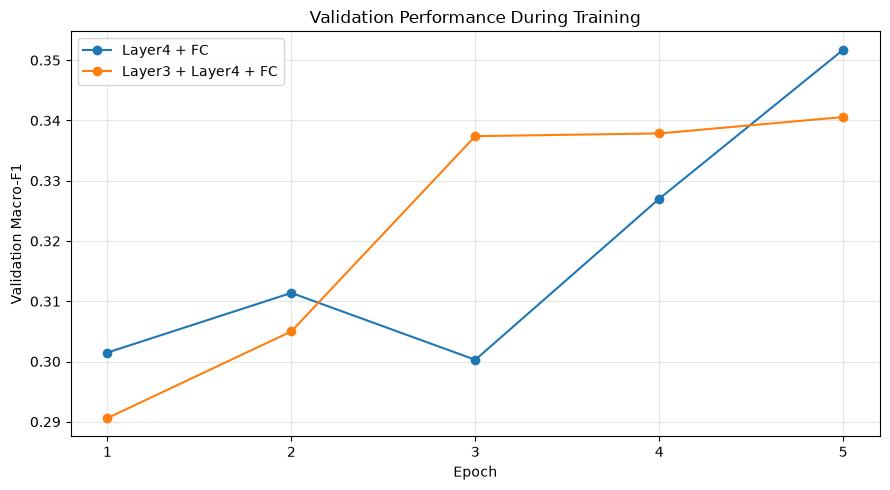

In [21]:

history_a = pd.DataFrame(result_a["History"])
history_b = pd.DataFrame(result_b["History"])

plt.figure(figsize=(9, 5))

plt.plot(
    history_a["epoch"],
    history_a["validation_macro_f1"],
    marker="o",
    label="Layer4 + FC"
)

plt.plot(
    history_b["epoch"],
    history_b["validation_macro_f1"],
    marker="o",
    label="Layer3 + Layer4 + FC"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("Validation Performance During Training")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


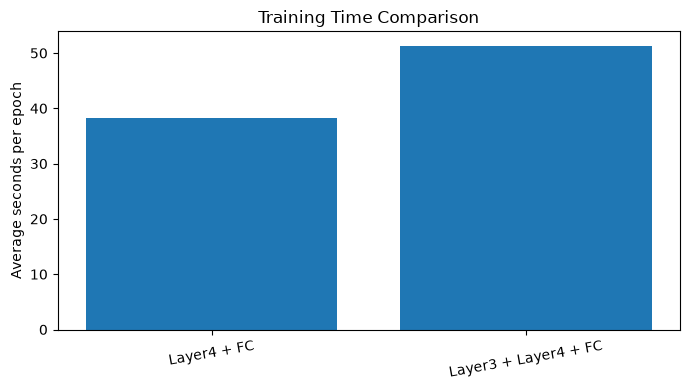

In [22]:

plt.figure(figsize=(7, 4))

plt.bar(
    comparison_df["Model"],
    comparison_df["Average seconds per epoch"]
)

plt.ylabel("Average seconds per epoch")
plt.title("Training Time Comparison")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Results and Discussion

Two transfer-learning configurations based on pretrained ResNet-18 were compared.

**Experiment A:** Only layer4 and the fully connected classification layer were unfrozen.

**Experiment B:** Layers 3 and 4, together with the fully connected classification layer, were unfrozen.

Both experiments used the same dataset split, preprocessing, batch size, learning rate of 0.0001, and five training epochs.

Experiment A achieved a best validation macro-F1 score of 0.3517 at epoch 5, with an average training time of approximately 38.20 seconds per epoch.

Experiment B achieved a best validation macro-F1 score of 0.3406 at epoch 4, with an average training time of approximately 51.36 seconds per epoch.

Unfreezing layer3 increased the average training time by approximately 34%, while the best validation macro-F1 decreased by 0.0111.

These results suggest that unfreezing additional layers did not improve validation performance in this experiment. The configuration with only layer4 and the classification head trainable provided a better balance between computational cost and validation performance.

The results are limited to five epochs and one train-validation split. Further experiments with different learning rates, longer training, and additional validation splits could provide more reliable conclusions.

The test set was kept separate from model selection and validation comparisons.

### Conclusion

The two ResNet-18 transfer learning configurations were compared using pretrained ImageNet weights, a learning rate of 0.0001, and five training epochs.

The first configuration unfroze `layer4` and the fully connected (`fc`) layer, resulting in **8,399,371 trainable parameters**. It achieved a best validation macro-F1 score of **0.3517**, with an average training time of **38.20 seconds per epoch**.

The second configuration unfroze `layer3`, `layer4`, and `fc`, resulting in **10,499,083 trainable parameters**. It achieved a best validation macro-F1 score of **0.3406**, with an average training time of **51.36 seconds per epoch**.

Unfreezing `layer3` increased the number of trainable parameters by approximately 25% and the average training time per epoch by 34.43%. However, validation macro-F1 decreased by 0.0112 rather than improving.

Overall, the `layer4 + fc` configuration performed better in this experiment. It achieved a higher validation macro-F1 while requiring fewer trainable parameters and less training time. This suggests that unfreezing additional layers did not provide a benefit under the current experimental settings.

The comparison used the validation set for model selection. The test set was kept separate and was not used during training or model selection.

In [3]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

checkpoint_dir = PROJECT_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Checkpoint folder:", checkpoint_dir)

Project root: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Checkpoint folder: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\checkpoints
